# 83 · Tuning the receding-horizon window: execute k of H = 16, with and without perturbations

In [1]:
import os, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import FlowPolicy, ChunkPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16

def bump_cube(env, obs, a):
    """Perturbation: at step 12 the target cube is shoved 3 cm sideways (someone bumps the table)."""
    if env.t == 12:
        import mujoco
        adr = env.model.jnt_qposadr[env.model.joint(f"cube_{env.task['obj']}").id]
        env.data.qpos[adr + 1] += 0.03
        mujoco.mj_forward(env.model, env.data)
    return a

In [2]:
ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
flow = FlowPolicy(horizon=H); flow.load_state_dict(torch.load("checkpoints/flow.pt", map_location=device)); flow.to(device).eval()
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
ks = [1, 2, 4, 8, 16]
rows = {"nominal": [], "cube bumped at step 12": []}
runs = {}
for k in ks:
    for cond, hook in [("nominal", None), ("cube bumped at step 12", bump_cube)]:
        t0 = time.time()
        r = evaluate(env, ChunkPolicy(flow, ds, env, device, execute=k, nfe=4), n_episodes=40, seed=50_000, on_step=hook)
        rows[cond].append(r["success"]); runs[(k, cond)] = r
        print(f"execute {k:2d}/16  {cond:24s} success {r['success']:.2f}  ({time.time() - t0:.0f}s, {40 * 50 // k} chunk calls approx.)")

execute  1/16  nominal                  success 0.90  (109s, 2000 chunk calls approx.)


execute  1/16  cube bumped at step 12   success 0.23  (297s, 2000 chunk calls approx.)


execute  2/16  nominal                  success 0.97  (38s, 1000 chunk calls approx.)


execute  2/16  cube bumped at step 12   success 0.28  (143s, 1000 chunk calls approx.)


execute  4/16  nominal                  success 1.00  (28s, 500 chunk calls approx.)


execute  4/16  cube bumped at step 12   success 0.20  (117s, 500 chunk calls approx.)


execute  8/16  nominal                  success 0.97  (24s, 250 chunk calls approx.)


execute  8/16  cube bumped at step 12   success 0.47  (74s, 250 chunk calls approx.)


execute 16/16  nominal                  success 1.00  (17s, 125 chunk calls approx.)


execute 16/16  cube bumped at step 12   success 0.53  (47s, 125 chunk calls approx.)


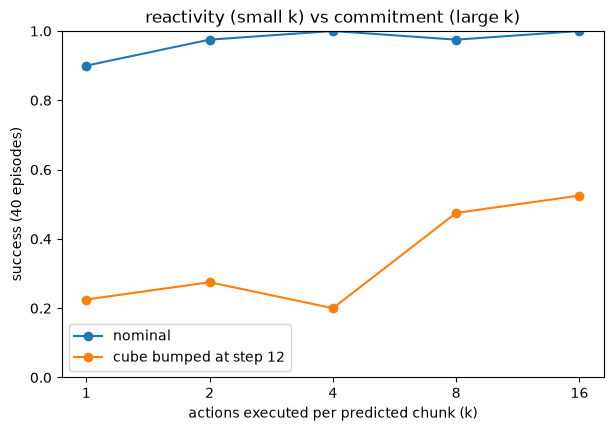

In [3]:
plt.figure(figsize=(7, 4.5))
for cond, s in rows.items():
    plt.plot(ks, s, "o-", label=cond)
plt.xscale("log", base=2); plt.xticks(ks, ks); plt.xlabel("actions executed per predicted chunk (k)"); plt.ylabel("success (40 episodes)")
plt.ylim(0, 1); plt.legend(); plt.title("reactivity (small k) vs commitment (large k)"); plt.show()

### Watch it: the cube gets bumped at step 12
Re-planning every step vs committing to the whole chunk, on an episode where the two disagree. Which one would you have bet on?

In [4]:
from vlacourse import showcase as sc
sc.compare(env, {"execute 1 of 16 (reactive)": ChunkPolicy(flow, ds, env, device, execute=1, nfe=4),
                  "execute 16 of 16 (committed)": ChunkPolicy(flow, ds, env, device, execute=16, nfe=4)},
           seed=sc.pick_seed(runs[(16, "cube bumped at step 12")], runs[(1, "cube bumped at step 12")], 50_000),
           on_step=bump_cube, title="83 bumped cube: reactive vs committed")

83 bumped cube: reactive vs committed: execute 1 of 16 (reactive): failed | execute 16 of 16 (committed): failed


[False, False]